In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
import pandas as pd

# 10-degree region comparison:
## Integration vs voxel-by-voxel

In [6]:
path_13 = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/Ratio testing FGN/"
path_12 = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/12CO/Ratio testing FGN/"

data_12_file = path_12 + "FGN_017_027_12CO_23arcsec_aligned_5res_nomagic.fits"
SNR_12_file  = path_12 + "FGN_017_027_12CO_23arcsec_aligned_5res_SNR.fits"

data_13_file = path_13 + "FGN_017_027_13CO_23arcsec_aligned_5res_nomagic.fits"
SNR_13_file  = path_13 + "FGN_017_027_13CO_23arcsec_aligned_5res_SNR.fits"

ratio_integ_file  = path_13 + "FGN_017_047_12_13_ratio_23arcsec_aligned_mean_collapsed_nomagic_13masked.fits"  # This was actually done in 30 degrees only
ratio_voxel_file = path_13 + "FGN_017_027_12_13_ratio_23arcsec_aligned_5res_13snr3.fits"

In [7]:
with fits.open(data_12_file) as hdul:
    data_12        = hdul[0].data
    data_12_header = hdul[0].header

with fits.open(SNR_12_file) as hdul:
    SNR_12        = hdul[0].data
    SNR_12_header = hdul[0].header
    
with fits.open(data_13_file) as hdul:
    data_13        = hdul[0].data
    data_13_header = hdul[0].header
    
    
with fits.open(SNR_13_file) as hdul:
    SNR_13        = hdul[0].data
    SNR_13_header = hdul[0].header

with fits.open(ratio_integ_file) as hdul:
    ratio_integ        = hdul[0].data
    ratio_integ_header = hdul[0].header
    
with fits.open(ratio_voxel_file) as hdul:
    ratio_voxel        = hdul[0].data
    ratio_voxel_header = hdul[0].header
    
ratio_voxel = ratio_voxel[~np.isnan(ratio_voxel)]
ratio_integ = ratio_integ[(~np.isnan(ratio_integ)) & (ratio_integ != 0)]

In [8]:
counts_ratio_integ , bin_ratio_integ = np.histogram(ratio_integ, bins = 50)
counts_ratio_voxel , bin_ratio_voxel = np.histogram(ratio_voxel, bins = 50)

In [9]:
mean_integ = np.mean(ratio_integ)
median_integ = np.median(ratio_integ)

mean_voxel = np.mean(ratio_voxel)
median_voxel = np.median(ratio_voxel)

integ_str = '\n'.join((f'Mean = {mean_integ:.2f}', f'Median = {median_integ:.2f}'))
voxel_str = '\n'.join((f'Mean = {mean_voxel:.2f}', f'Median = {median_voxel:.2f}'))

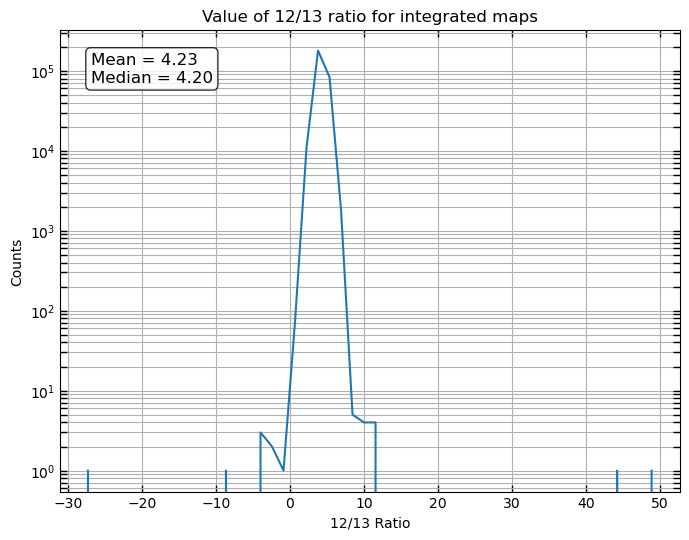

In [10]:
# Plot the histogram as a line
plt.figure(figsize=(8, 6))

# Use bin centers for plotting
bin_centers_integ = 0.5 * (bin_ratio_integ[:-1] + bin_ratio_integ[1:])
plt.plot(bin_centers_integ, counts_ratio_integ, label='12/13 Ratio integrated method')
# Set logarithmic scale for both axes
#plt.xscale('log')
plt.yscale('log')
plt.grid(True, which='both')
ax = plt.gca()
plt.xlabel('12/13 Ratio')
plt.ylabel('Counts')
plt.title('Value of 12/13 ratio for integrated maps')
plt.text(0.05, 0.95, integ_str,
         transform=plt.gca().transAxes,   # relative coords (0–1)
         fontsize=12,
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.tick_params(axis='both',          # Apply to both x and y axes
               which='both',         # Apply to both major and minor ticks
               length=5,            # Length of ticks
               width=1,              # Width of ticks
               colors='black',       # Color of ticks
               direction='in',    # Direction of ticks (in, out, or inout)
               top=True,             # Show top ticks
               right=True) 

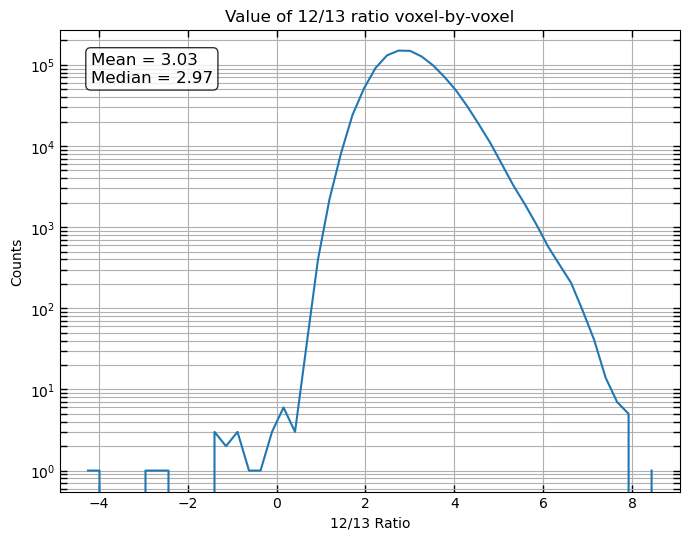

In [11]:
# Plot the histogram as a line
plt.figure(figsize=(8, 6))

# Use bin centers for plotting
bin_centers_voxel = 0.5 * (bin_ratio_voxel[:-1] + bin_ratio_voxel[1:])
plt.plot(bin_centers_voxel, counts_ratio_voxel, label='12/13 Ratio voxel-by-voxel method')
# Set logarithmic scale for both axes
#plt.xscale('log')
plt.yscale('log')
plt.grid(True, which='both')
ax = plt.gca()
plt.xlabel('12/13 Ratio')
plt.ylabel('Counts')
plt.title('Value of 12/13 ratio voxel-by-voxel')
plt.text(0.05, 0.95, voxel_str,
         transform=plt.gca().transAxes,   # relative coords (0–1)
         fontsize=12,
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.tick_params(axis='both',          # Apply to both x and y axes
               which='both',         # Apply to both major and minor ticks
               length=5,            # Length of ticks
               width=1,              # Width of ticks
               colors='black',       # Color of ticks
               direction='in',    # Direction of ticks (in, out, or inout)
               top=True,             # Show top ticks
               right=True) 

# 30-degree region

In [12]:
path_13 = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/Ratio testing FGN/"
path_12 = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/12CO/Ratio testing FGN/"

data_12_file = path_12 + "FGN_017_047_12CO_23arcsec_aligned_5res_nomagic.fits"
SNR_12_file  = path_12 + "FGN_017_047_12CO_23arcsec_aligned_5res_SNR.fits"

data_13_file = path_13 + "FGN_017_047_13CO_23arcsec_aligned_5res_nomagic.fits"
SNR_13_file  = path_13 + "FGN_017_047_13CO_23arcsec_aligned_5res_SNR.fits"

ratio_integ_file  = path_13 + "FGN_017_047_12_13_ratio_23arcsec_aligned_mean_collapsed_nomagic_13masked.fits"
ratio_voxel_file = path_13 + "FGN_017_047_12_13_ratio_23arcsec_aligned_5res_13snr3.fits"

In [13]:
with fits.open(data_12_file) as hdul:
    data_12        = hdul[0].data
    data_12_header = hdul[0].header

with fits.open(SNR_12_file) as hdul:
    SNR_12        = hdul[0].data
    SNR_12_header = hdul[0].header
    
with fits.open(data_13_file) as hdul:
    data_13        = hdul[0].data
    data_13_header = hdul[0].header
    
    
with fits.open(SNR_13_file) as hdul:
    SNR_13        = hdul[0].data
    SNR_13_header = hdul[0].header

with fits.open(ratio_integ_file) as hdul:
    ratio_integ        = hdul[0].data
    ratio_integ_header = hdul[0].header
    
with fits.open(ratio_voxel_file) as hdul:
    ratio_voxel        = hdul[0].data
    ratio_voxel_header = hdul[0].header
    
ratio_voxel = ratio_voxel[~np.isnan(ratio_voxel)]
ratio_voxel = ratio_voxel[ratio_voxel < 20] # Completely arbitrary but there is 1 outlier that messes this up
ratio_voxel = ratio_voxel[ratio_voxel > -5] # Completely arbitrary but there is 1 outlier that messes this up
ratio_integ = ratio_integ[(~np.isnan(ratio_integ)) & (ratio_integ != 0)]

In [14]:
counts_ratio_integ , bin_ratio_integ = np.histogram(ratio_integ, bins = 50)
counts_ratio_voxel , bin_ratio_voxel = np.histogram(ratio_voxel, bins = 50)

In [15]:
mean_integ = np.mean(ratio_integ)
median_integ = np.median(ratio_integ)

mean_voxel = np.mean(ratio_voxel)
median_voxel = np.median(ratio_voxel)

integ_str = '\n'.join((f'Mean = {mean_integ:.2f}', f'Median = {median_integ:.2f}'))
voxel_str = '\n'.join((f'Mean = {mean_voxel:.2f}', f'Median = {median_voxel:.2f}'))

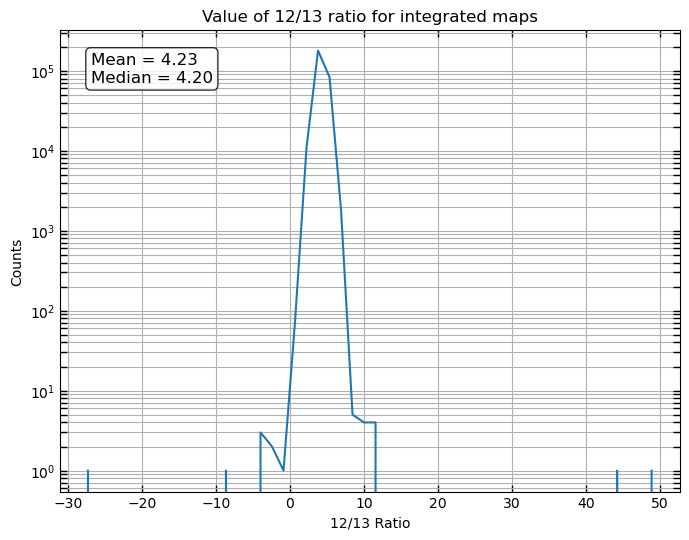

In [16]:
# Plot the histogram as a line
plt.figure(figsize=(8, 6))

# Use bin centers for plotting
bin_centers_integ = 0.5 * (bin_ratio_integ[:-1] + bin_ratio_integ[1:])
plt.plot(bin_centers_integ, counts_ratio_integ, label='12/13 Ratio integrated method')
# Set logarithmic scale for both axes
#plt.xscale('log')
plt.yscale('log')
plt.grid(True, which='both')
ax = plt.gca()
plt.xlabel('12/13 Ratio')
plt.ylabel('Counts')
plt.title('Value of 12/13 ratio for integrated maps')
plt.text(0.05, 0.95, integ_str,
         transform=plt.gca().transAxes,   # relative coords (0–1)
         fontsize=12,
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.tick_params(axis='both',          # Apply to both x and y axes
               which='both',         # Apply to both major and minor ticks
               length=5,            # Length of ticks
               width=1,              # Width of ticks
               colors='black',       # Color of ticks
               direction='in',    # Direction of ticks (in, out, or inout)
               top=True,             # Show top ticks
               right=True) 

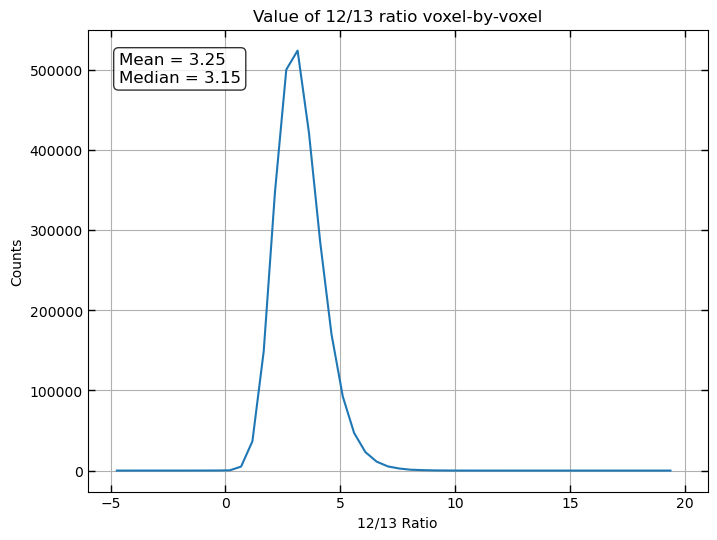

In [17]:
# Plot the histogram as a line
plt.figure(figsize=(8, 6))

# Use bin centers for plotting
bin_centers_voxel = 0.5 * (bin_ratio_voxel[:-1] + bin_ratio_voxel[1:])
plt.plot(bin_centers_voxel, counts_ratio_voxel, label='12/13 Ratio voxel-by-voxel method')
# Set logarithmic scale for both axes
#plt.xscale('log')
#plt.yscale('log')
plt.grid(True, which='both')
ax = plt.gca()
plt.xlim([-6,21])
plt.xlabel('12/13 Ratio')
plt.ylabel('Counts')
plt.title('Value of 12/13 ratio voxel-by-voxel')
plt.text(0.05, 0.95, voxel_str,
         transform=plt.gca().transAxes,   # relative coords (0–1)
         fontsize=12,
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.tick_params(axis='both',          # Apply to both x and y axes
               which='both',         # Apply to both major and minor ticks
               length=5,            # Length of ticks
               width=1,              # Width of ticks
               colors='black',       # Color of ticks
               direction='in',    # Direction of ticks (in, out, or inout)
               top=True,             # Show top ticks
               right=True) 

In [137]:
snr_lim = 3

mask_snr_13 = SNR_13 > snr_lim

data_12_masked = data_12[mask_snr_13]
data_13_masked = data_13[mask_snr_13]

In [120]:
max_val = np.nanmax(SNR_13)
z, y, x = np.unravel_index(np.nanargmax(SNR_13), SNR_13.shape)

print(max_val)
print(x, y, z)
print(SNR_13[z, y, x])

1881.0349
1071 3 41
1881.0349


In [149]:
ratio = np.full_like(data_12, 0, dtype=float)

mask = (SNR_13 > snr_lim) & np.isfinite(data_13) & np.isfinite(data_12) & (data_13 != 0)

ratio[mask] = data_12[mask] / data_13[mask]

In [150]:
np.shape(ratio)

(48, 679, 18608)

In [196]:
nv, nb, nl = ratio.shape

df = pd.DataFrame({
    'value': ratio.ravel(),
    'v': np.repeat(np.arange(nv), nb * nl),
    'b': np.tile(np.repeat(np.arange(nb), nl), nv),
    'l': np.tile(np.arange(nl), nv * nb)
})

In [183]:
max_val = np.nanmax(ratio)
z, y, x = np.unravel_index(np.nanargmax(ratio), ratio.shape)

print(max_val)
print(x, y, z)
print(ratio[z, y, x])

1542848.0
1071 3 21
1542848.0


In [198]:
val = df.loc[
    (df['l'] == 1071) & (df['b'] == 3) & (df['v'] == 21),
    'value'
].iloc[0]
#val == df['value'].max()

In [199]:
val

1542848.0

In [216]:
l_pix = df['l'].to_numpy()

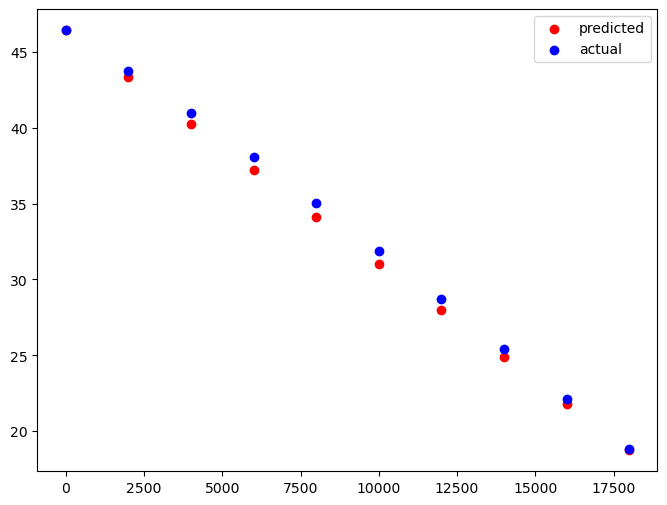

In [225]:
pixels = [0,2000,4000,6000,8000,10000,12000,14000,16000,18000]
predicted = [46.413,	43.339,	40.265,	37.191,	34.117,	31.043,	27.969,	24.895,	21.821,	18.747]
actual = [46.413,	43.74,	40.945,	38.034,	35.015,	31.899,	28.703,	25.44,	22.135,	18.807]

plt.figure(figsize=(8, 6))
plt.scatter(pixels, predicted, color = 'red', label ='predicted')
plt.scatter(pixels, actual, color = 'blue', label='actual')
plt.legend()

In [ ]:
# Build a dataframe from a 3D ratio cube: one row per (l,b,v) voxel
# Columns: value, l, b, v
cube = ratio
header_for_wcs = data_13_header


# Keep finite voxels and drop zeros by default (zeros are usually masked/background in your workflow)
mask = np.isfinite(cube) & (cube != 0)
z, y, x = np.where(mask)
values = cube[z, y, x]

# Convert voxel indices -> world coordinates (l,b,v)
w = WCS(header_for_wcs, naxis=3)
l, b, v = w.all_pix2world(x, y, z, 0)

ratio_df = pd.DataFrame({
    'value': values,
    'l': l,
    'b': b,
    'v': v
})

print(f'Cube shape (v,b,l): {cube.shape}')
print(f'DataFrame rows: {len(ratio_df):,}')
ratio_df.head()

In [235]:
ratio_df['v'].min()

-51160.07891398668

In [248]:
with fits.open('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_047_13CO_23arcsec_aligned_5res.fits', mode='update') as hdul:
    hdul[0].header.append(('CUNIT3', "km/s"))

# 2 degree approach

In [107]:
## Trim the cubes first to the range where we have emission! 12 and 13, load the trimmed cubes here
## Do SNR too but let's start with trimming
## Maybe also do SNR while we have the cubes downloaded

path_13 = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"
path_12 = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/12CO/"
region  = "018"
file_13 = path_13 +f"FGN_{region}_13CO_23arcsec_aligned_trimmed.fits"
file_12 = path_12 +f"FGN_{region}_12CO_23arcsec_aligned_trimmed.fits"
#file_13 = path_13 + f"FGN_{region}_13CO_23arcsec_aligned_nomagic.fits"
#file_12 = path_12 + f"FGN_{region}_12CO_23arcsec_aligned_nomagic.fits"
SNR_filename = path_13 + f"FGN_{region}_13CO_23arcsec_aligned_SNR_trimmed.fits"

with fits.open(file_13) as hdul:
    data_13        = hdul[0].data
    data_13_header = hdul[0].header

with fits.open(file_12) as hdul:
    data_12        = hdul[0].data
    data_12_header = hdul[0].header

In [108]:
ratio = data_12 / data_13
ratio_1d = np.ravel(ratio)

In [109]:
print(np.sum(data_12) / np.sum(data_13))
print(np.sum(data_12))
print(np.sum(data_13))

5.455559
117990110.0
21627502.0


In [33]:
np.shape(data_12)

(279, 601, 1201)

In [34]:
np.shape(data_13)

(279, 601, 1201)

In [35]:
CRVAL1 = data_13_header['CRVAL1']
CRPIX1 = data_13_header['CRPIX1']
CDELT1 = data_13_header['CDELT1']

CRVAL2 = data_13_header['CRVAL2']
CRPIX2 = data_13_header['CRPIX2']
CDELT2 = data_13_header['CDELT2']

CRVAL3 = data_13_header['CRVAL3']
CRPIX3 = data_13_header['CRPIX3']
CDELT3 = data_13_header['CDELT3']

In [36]:
## I am thinking 601 pixels for 1 degree means 60 piels per degree...
low_l  = float(region[1:]) - 1
high_l = low_l + 2

low_b  = -0.5
high_b = 0.5

low_v  = CRVAL3 + (1 - CRPIX3) * CDELT3
high_v = CRVAL3 + (data_13_header['NAXIS3'] - CRPIX3) * CDELT3

In [37]:
nv, nb, nl = data_13.shape

# Create bin edges (indices)
v_bins = np.linspace(0, nv, 11, dtype=int)
b_bins = np.linspace(0, nb, 11, dtype=int)
l_bins = np.linspace(0, nl, 11, dtype=int)

# Output arrays
sum_v_13 = np.zeros(10)
sum_b_13 = np.zeros(10)
sum_l_13 = np.zeros(10)

sum_v_12 = np.zeros(10)
sum_b_12 = np.zeros(10)
sum_l_12 = np.zeros(10)

edges_l = np.zeros(10)
edges_b = np.zeros(10)
edges_v = np.zeros(10)

# ---- Velocity bins 13 ----
for i in range(10):
    v_start, v_end = v_bins[i], v_bins[i+1]
    subcube = data_13[v_start:v_end, :, :]
    sum_v_13[i] = np.nansum(subcube)
    v_cen = (v_start + v_end) / 2
    edges_v[i] = v_cen

# ---- Latitude bins 13 ----
for i in range(10):
    b_start, b_end = b_bins[i], b_bins[i+1]
    subcube = data_13[:, b_start:b_end, :]
    sum_b_13[i] = np.nansum(subcube)
    b_cen = (b_start + b_end) / 2
    edges_b[i] = b_cen

# ---- Longitude bins 13 ----
for i in range(10):
    l_start, l_end = l_bins[i], l_bins[i+1]
    subcube = data_13[:, :, l_start:l_end]
    sum_l_13[i] = np.nansum(subcube)
    l_cen = (l_start + l_end) / 2
    edges_l[i] = l_cen

# ---- Velocity bins 12 ----
for i in range(10):
    v_start, v_end = v_bins[i], v_bins[i+1]
    subcube = data_12[v_start:v_end, :, :]
    sum_v_12[i] = np.nansum(subcube)

# ---- Latitude bins 12 ----
for i in range(10):
    b_start, b_end = b_bins[i], b_bins[i+1]
    subcube = data_12[:, b_start:b_end, :]
    sum_b_12[i] = np.nansum(subcube)

# ---- Longitude bins 12 ----
for i in range(10):
    l_start, l_end = l_bins[i], l_bins[i+1]
    subcube = data_12[:, :, l_start:l_end]
    sum_l_12[i] = np.nansum(subcube)

In [38]:
edges_l

l_values = CRVAL1 + (edges_l - CRPIX1) * CDELT1

In [39]:
edges_b

b_values = CRVAL2 + (edges_b - CRPIX2) * CDELT2

In [40]:
edges_v

v_values = CRVAL3 + (edges_v - CRPIX3) * CDELT3

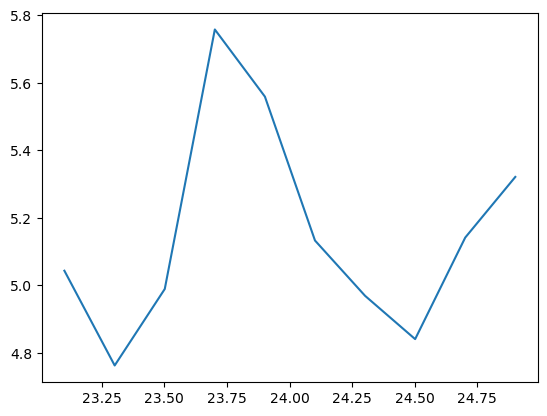

In [41]:
ratio_l = sum_l_12 / sum_l_13
plt.plot(l_values, ratio_l)

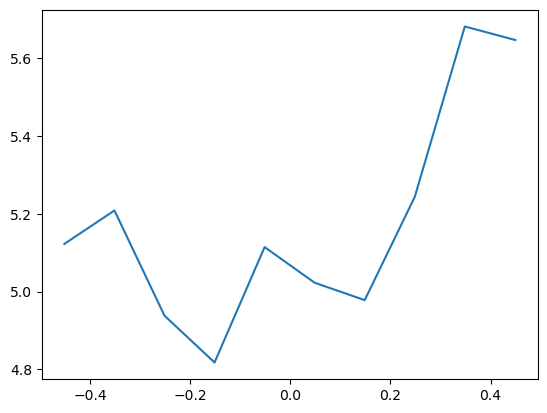

In [42]:
ratio_b = sum_b_12 / sum_b_13
plt.plot(b_values, ratio_b)

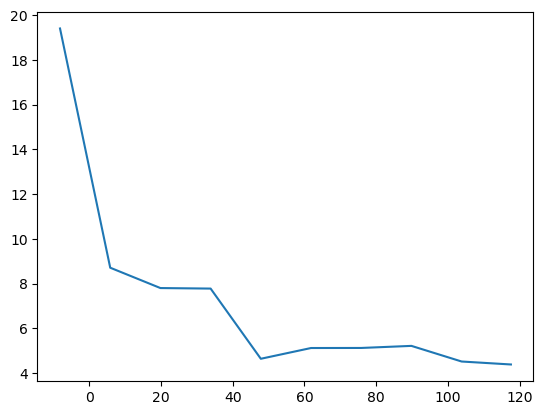

In [43]:
ratio_v = sum_v_12 / sum_v_13
plt.plot(v_values, ratio_v)

In [44]:
b_values

array([-0.45131333, -0.35131333, -0.25131333, -0.15131333, -0.05131333,
        0.04868667,  0.14868667,  0.24868667,  0.34868667,  0.44952   ])

In [45]:
df_l_18 = pd.DataFrame({
    'l_values': l_values,
    'sum_l_12': sum_l_12,
    'sum_l_13': sum_l_13,
    'ratio_l': ratio_l
})

df_l_18 = df_l_18.iloc[::-1].reset_index(drop=True)
df_l_18

,l_values,sum_l_12,sum_l_13,ratio_l
0,23.100797,30981918.0,6143314.5,5.043193
1,23.301630,34021904.0,7143701.0,4.762504
2,23.501630,33943596.0,6803589.5,4.989072
3,23.701630,30554768.0,5306580.5,5.757902
4,23.901630,30699718.0,5522578.5,5.558946
5,24.101630,32334780.0,6299762.0,5.132699
6,24.301630,33755624.0,6793388.5,4.968894
7,24.501630,34735308.0,7175829.0,4.840599
8,24.701630,27968498.0,5439841.0,5.141418
9,24.901630,22479898.0,4224663.5,5.321110


In [19]:
for i in range(10):
    l_start, l_end = l_bins[i], l_bins[i+1]
    print(l_start, l_end)
    l_start = l_values = CRVAL1 + (l_start - CRPIX1) * CDELT1
    l_end = l_values = CRVAL1 + (l_end - CRPIX1) * CDELT1
    print(l_start, l_end)

0 120
21.00151666667019 20.801516666669485
120 240
20.801516666669485 20.601516666668783
240 360
20.601516666668783 20.40151666666808
360 480
20.40151666666808 20.201516666667377
480 600
20.201516666667377 20.00151666666667
600 720
20.00151666666667 19.801516666665968
720 840
19.801516666665968 19.601516666665265
840 960
19.601516666665265 19.401516666664563
960 1080
19.401516666664563 19.201516666663856
1080 1201
19.201516666663856 18.99984999999648


In [20]:
for i in range(10):
    b_start, b_end = b_bins[i], b_bins[i+1]
    print(b_start, b_end)
    b_start = b_values = CRVAL2 + (b_start - CRPIX2) * CDELT2
    b_end = b_values = CRVAL2 + (b_end - CRPIX2) * CDELT2
    print(b_start, b_end)

0 60
-0.5014100000028463 -0.40141000000250526
60 120
-0.40141000000250526 -0.30141000000216434
120 180
-0.30141000000216434 -0.2014100000018233
180 240
-0.2014100000018233 -0.10141000000148231
240 300
-0.10141000000148231 -0.0014100000011413316
300 360
-0.0014100000011413316 0.09858999999919968
360 420
0.09858999999919968 0.19858999999954066
420 480
0.19858999999954066 0.2985899999998817
480 540
0.2985899999998817 0.39859000000022266
540 601
0.39859000000022266 0.500256666667236


In [21]:
for i in range(10):
    v_start, v_end = v_bins[i], v_bins[i+1]
    print(v_start, v_end)
    v_start = v_values = CRVAL3 + (v_start - CRPIX3) * CDELT3
    v_end = v_values = CRVAL3 + (v_end - CRPIX3) * CDELT3
    print(v_start, v_end)

0 29
132.50206073830486 118.00206073906156
29 59
118.00206073906156 103.00206073981826
59 89
103.00206073981826 88.00206074057496
89 118
88.00206074057496 73.50206074130256
118 148
73.50206074130256 58.50206074205926
148 178
58.50206074205926 43.50206074281596
178 207
43.50206074281596 29.002060743543552
207 237
29.002060743543552 14.002060744300252
237 267
14.002060744300252 -0.9979392549430486
267 297
-0.9979392549430486 -15.997939254157245


In [22]:
sum_v_12

array([ 8493568.   ,  7021602.5  ,  8839983.   , 17928450.   ,
       33879192.   , 28354118.   , 24283774.   , 31095424.   ,
       16566169.   ,  1005962.875])

In [23]:
def sum_extractor(cube_13, cube_12, Mask, snr_cube):
    with fits.open(cube_13) as hdul:
        data_13        = hdul[0].data
        data_13_header = hdul[0].header

    with fits.open(cube_12) as hdul:
        data_12        = hdul[0].data
        data_12_header = hdul[0].header

    region = file_13[57:60]
    print(Mask)

    if Mask == True:
        with fits.open(snr_cube) as hdul:
            snr = hdul[0].data

        mask    = snr > 2
        data_13 = np.where(mask, data_13, 0)
        data_12 = np.where(mask, data_12, 0)


    total_ratio = np.sum(data_12) / np.sum(data_13)

    CRVAL1 = data_13_header['CRVAL1']
    CRPIX1 = data_13_header['CRPIX1']
    CDELT1 = data_13_header['CDELT1']

    CRVAL2 = data_13_header['CRVAL2']
    CRPIX2 = data_13_header['CRPIX2']
    CDELT2 = data_13_header['CDELT2']

    CRVAL3 = data_13_header['CRVAL3']
    CRPIX3 = data_13_header['CRPIX3']
    CDELT3 = data_13_header['CDELT3']

    low_l  = float(region[1:]) - 1
    high_l = low_l + 2

    low_b  = -0.5
    high_b = 0.5

    low_v  = CRVAL3 + (1 - CRPIX3) * CDELT3
    high_v = CRVAL3 + (data_13_header['NAXIS3'] - CRPIX3) * CDELT3

    print(f'Longitude limits = {low_l:.2f} - {high_l:.2f}')
    print(f'Latitude limits = {low_b:.2f} - {high_b:.2f}')
    print(f'Velocity limits = {low_v:.2f} - {high_v:.2f}')

    nv, nb, nl = data_13.shape

    # Create bin edges (indices)
    v_bins = np.linspace(0, nv, 11, dtype=int)
    b_bins = np.linspace(0, nb, 11, dtype=int)
    l_bins = np.linspace(0, nl, 11, dtype=int)

    # Output arrays
    sum_v_13 = np.zeros(10)
    sum_b_13 = np.zeros(10)
    sum_l_13 = np.zeros(10)

    sum_v_12 = np.zeros(10)
    sum_b_12 = np.zeros(10)
    sum_l_12 = np.zeros(10)

    edges_l = np.zeros(10)
    edges_b = np.zeros(10)
    edges_v = np.zeros(10)

    # ---- Velocity bins 13 ----
    for i in range(10):
        v_start, v_end = v_bins[i], v_bins[i+1]
        subcube = data_13[v_start:v_end, :, :]
        sum_v_13[i] = np.nansum(subcube)
        v_cen = (v_start + v_end) / 2 + 1
        edges_v[i] = v_cen

    # ---- Latitude bins 13 ----
    for i in range(10):
        b_start, b_end = b_bins[i], b_bins[i+1]
        subcube = data_13[:, b_start:b_end, :]
        sum_b_13[i] = np.nansum(subcube)
        b_cen = (b_start + b_end) / 2 + 1
        edges_b[i] = b_cen

    # ---- Longitude bins 13 ----
    for i in range(10):
        l_start, l_end = l_bins[i], l_bins[i+1]
        subcube = data_13[:, :, l_start:l_end]
        sum_l_13[i] = np.nansum(subcube)
        l_cen = (l_start + l_end) / 2 + 1
        edges_l[i] = l_cen

    # ---- Velocity bins 12 ----
    for i in range(10):
        v_start, v_end = v_bins[i], v_bins[i+1]
        subcube = data_12[v_start:v_end, :, :]
        sum_v_12[i] = np.nansum(subcube)

    # ---- Latitude bins 12 ----
    for i in range(10):
        b_start, b_end = b_bins[i], b_bins[i+1]
        subcube = data_12[:, b_start:b_end, :]
        sum_b_12[i] = np.nansum(subcube)

    # ---- Longitude bins 12 ----
    for i in range(10):
        l_start, l_end = l_bins[i], l_bins[i+1]
        subcube = data_12[:, :, l_start:l_end]
        sum_l_12[i] = np.nansum(subcube)

    l_values = CRVAL1 + (edges_l - CRPIX1) * CDELT1
    b_values = CRVAL2 + (edges_b - CRPIX2) * CDELT2
    v_values = CRVAL3 + (edges_v - CRPIX3) * CDELT3

    ratio_l = np.full_like(sum_l_12, 0)
    ratio_b = np.full_like(sum_b_12, 0)
    ratio_v = np.full_like(sum_v_12, 0)

    # ---- Longitude ----
    ratio_l[sum_l_13 != 0] = sum_l_12[sum_l_13 != 0] / sum_l_13[sum_l_13 != 0]
    plt.figure()
    plt.plot(l_values, ratio_l)
    plt.xlabel('l (degrees)')
    plt.ylabel('ratio')
    plt.title('Ratio vs Longitude')
    plt.show()

    # ---- Latitude ----
    ratio_b[sum_b_13 != 0] = sum_b_12[sum_b_13 != 0] / sum_b_13[sum_b_13 != 0]
    plt.figure()
    plt.plot(b_values, ratio_b)
    plt.xlabel('b (degrees)')
    plt.ylabel('ratio')
    plt.title('Ratio vs Latitude')
    plt.show()

    # ---- Velocity ----
    ratio_v[sum_v_13 != 0] = sum_v_12[sum_v_13 != 0] / sum_v_13[sum_v_13 != 0]
    plt.figure()
    plt.plot(v_values, ratio_v)
    plt.xlabel('v (km/s)')
    plt.ylabel('ratio')
    plt.title('Ratio vs Velocity')
    plt.show()

    df_l = pd.DataFrame({
    'l_values': l_values,
    'sum_l_12': sum_l_12,
    'sum_l_13': sum_l_13,
    'ratio_l': ratio_l
    })

    df_l = df_l.iloc[::-1].reset_index(drop=True)

    df_b = pd.DataFrame({
    'b_values': b_values,
    'sum_b_12': sum_b_12,
    'sum_b_13': sum_b_13,
    'ratio_b': ratio_b
    })

    df_v = pd.DataFrame({
    'v_values': v_values,
    'sum_v_12': sum_v_12,
    'sum_v_13': sum_v_13,
    'ratio_v': ratio_v
    })

    #l_name_1 = path_13 + "Ratio testing FGN/" + f"FGN_12_13_{region}_longitude_ratio_trimmed.csv"
    #b_name_1 = path_13 + "Ratio testing FGN/" + f"FGN_12_13_{region}_latitude_ratio_trimmed.csv"
    #v_name_1 = path_13 + "Ratio testing FGN/" + f"FGN_12_13_{region}_velocity_ratio_trimmed.csv"
    
    l_name_1 = path_13 + "Ratio testing FGN/" + f"FGN_12_13_{region}_longitude_ratio_masked_2.csv"
    b_name_1 = path_13 + "Ratio testing FGN/" + f"FGN_12_13_{region}_latitude_ratio_masked_2.csv"
    v_name_1 = path_13 + "Ratio testing FGN/" + f"FGN_12_13_{region}_velocity_ratio_masked_2.csv"

    l_name_2 = path_13 + "Ratio testing FGN/" + f"FGN_12_13_{region}_longitude_ratio_masked.csv"
    b_name_2 = path_13 + "Ratio testing FGN/" + f"FGN_12_13_{region}_latitude_ratio_masked.csv"
    v_name_2 = path_13 + "Ratio testing FGN/" + f"FGN_12_13_{region}_velocity_ratio_masked.csv"

    if "trimmed" in file_13:
        df_l.to_csv(l_name_1, index= False)
        df_b.to_csv(b_name_1, index= False)
        df_v.to_csv(v_name_1, index= False)
    elif "nomagic" in file_13:
        df_l.to_csv(l_name_2, index= False)
        df_b.to_csv(b_name_2, index= False)
        df_v.to_csv(v_name_2, index= False)
    else:
        print('Wrong name')

    return total_ratio, df_l, df_b, df_v

True
Longitude limits = 17.00 - 19.00
Latitude limits = -0.50 - 0.50
Velocity limits = 145.09 - -14.91


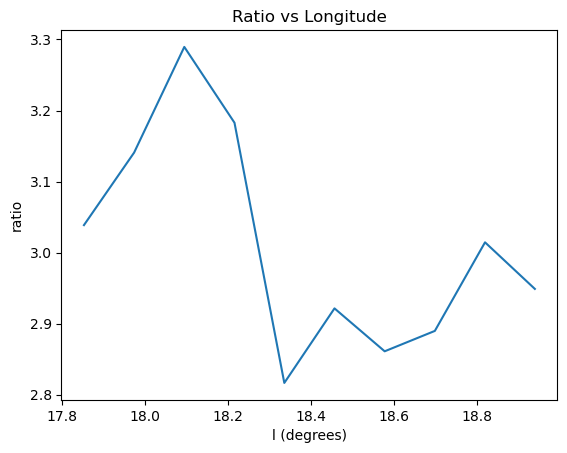

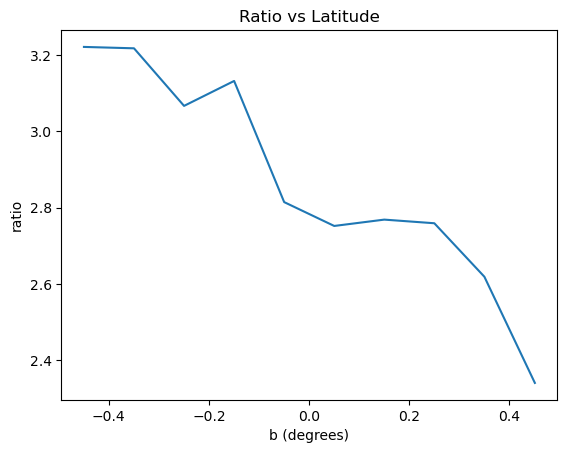

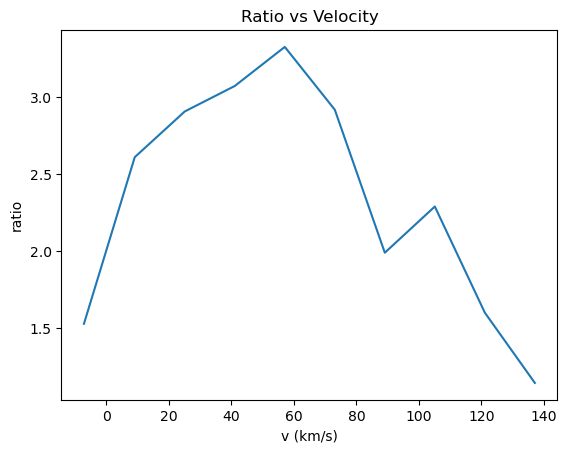

In [110]:
Mask = "trimmed" in file_13
test_ratio_1, test_l_1, test_b_1, test_v_1 = sum_extractor(file_13, file_12, Mask, SNR_filename)

In [209]:
np.sum(sum_v_12)

7974993.745204806

In [152]:
np.sum(data_13)

59741760.0

In [132]:
np.abs((np.sum(sum_v_13) - np.sum(data_13))/ np.sum(data_13)) * 100

0.00018357702614014323

In [153]:
test_ratio_1

2.635598

In [21]:
file_12

'/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/12CO/FGN_018_12CO_23arcsec_aligned_13snr3_masked_nomagic.fits'

In [20]:
test_ratio

5.455559

In [172]:
hdu = fits.PrimaryHDU(data=data_13, header=data_13_header)
hdu.writeto(path_13 + '13_masked.fits', overwrite=True)

In [163]:
file_13_kappa = path_13 + f"FGN_{region}_13CO_23arcsec_aligned_nomagic_masked.fits"
file_12_kappa = path_12 + f"FGN_{region}_12CO_23arcsec_aligned_nomagic_masked.fits"

with fits.open(file_13_kappa) as hdul:
    data_13_kappa        = hdul[0].data

with fits.open(file_12_kappa) as hdul:
    data_12_kappa        = hdul[0].data

In [170]:
diff = np.abs(data_12 - data_12_kappa)

print("Max difference:", np.nanmax(diff))
print("Nonzero differences:", np.sum(diff != 0))

Max difference: 0.0
Nonzero differences: 0


In [142]:
test_v_1

,v_values,sum_v_12,sum_v_13,ratio_v
0,136.575021,2.733695e+02,3.017239e+02,0.906025
1,117.325021,1.394526e+06,6.201441e+05,2.248712
2,98.075021,1.696424e+06,8.084609e+05,2.098337
3,78.825021,8.620184e+06,3.066868e+06,2.810745
4,59.575021,4.537113e+06,1.793707e+06,2.529462
5,40.325021,1.203287e+06,4.442728e+05,2.708442
6,21.075021,7.517569e+05,2.947242e+05,2.550713
7,1.825021,6.398575e+05,2.518837e+05,2.540289
8,-17.424979,1.031368e+03,8.688656e+02,1.187028
9,-36.674979,-1.485724e+01,1.259473e+02,-0.117964


In [248]:
np.size(data_12)

246500150

In [55]:
with fits.open(SNR_filename) as hdul:
    snr = hdul[0].data

    mask    = snr > 2

In [56]:
np.size(mask)

202826081

In [247]:
len(data_12)

325

In [272]:
data_12_mask = data_12[mask]

In [273]:
np.mean(data_12_mask)

6.1421866

In [300]:
np.sum(data_12) / np.sum(data_12[snr>3])

10.891159

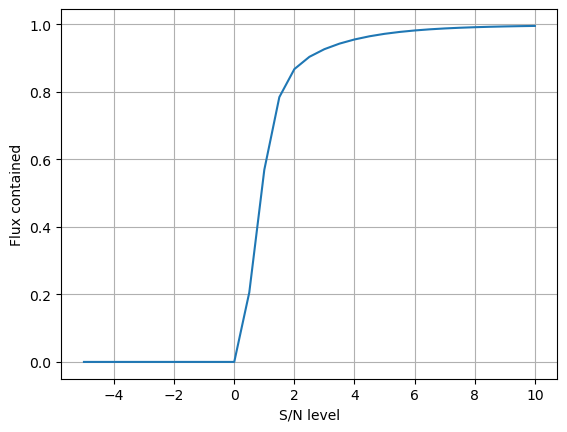

In [378]:
lim = np.linspace(-5,10,num = 31)
snr_contained = np.zeros(len(lim))

mask_13_0 = data_13 > 0
data_13_0 = np.where(mask_13_0, data_13, 0)

for i in range(len(lim)):
    snr_contained[i] = np.sum(data_13_0[snr>lim[i]]) / np.sum(data_13_0)

plt.figure()
plt.plot(lim, 1-snr_contained)
plt.xlabel('S/N level')
plt.ylabel('Flux contained')
plt.grid("On")
plt.show()

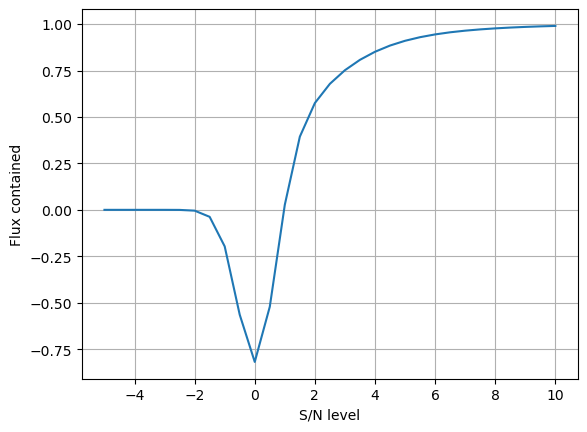

In [61]:
lim = np.linspace(-5,10,num = 31)
snr_contained = np.zeros(len(lim))

for i in range(len(lim)):
    snr_contained[i] = np.sum(data_13[snr<lim[i]]) / np.sum(data_13)

plt.figure()
plt.plot(lim, snr_contained)
plt.xlabel('S/N level')
plt.ylabel('Flux contained')
plt.grid("On")
plt.show()

In [339]:
limit = 0

print(np.sum(np.abs(data_13[snr> limit])) / np.sum(np.abs(data_13)))
print(np.sum(data_12[snr> limit]) / np.sum(data_12))

0.6229858
0.78834146


In [319]:
np.shape(snr)

(325, 601, 1262)

In [347]:
np.shape(data_13)

(325, 601, 1262)

In [351]:
print(np.sum(data_13)/2)
print(np.sum(data_13_0)/2)

8442740.0
21383266.0


In [406]:
snr_contained

array([2.53273368, 2.28448844, 1.69342601, 1.09070265, 0.6769489 ,
       0.45119989, 0.33497339, 0.26780427, 0.22130051, 0.1853054 ,
       0.15626472, 0.13249108, 0.11257599, 0.09599167, 0.08199568,
       0.07026666, 0.06043983, 0.05217896, 0.04512794, 0.03918396,
       0.03411572, 0.02987174, 0.02628879, 0.02322716, 0.02062656,
       0.01837117, 0.01643071, 0.0147383 , 0.01329025, 0.0120563 ,
       0.01095717])

In [383]:
snr_contained[14] * np.sum(data_13) / 2

2828093.279811144

In [384]:
snr_contained[14]

0.33497339487075806